# Семинар 5. Детекция и сегментация на ultralytics

На лекции мы разобрали, как устроены детекторы изнутри. На практике их почти
никто не пишет с нуля: берут готовую библиотеку, дообучают на своих данных
и выкатывают. Самая ходовая такая библиотека — **ultralytics** (YOLO).
На семинаре мы пройдём этот путь целиком, на машинах.

**План:**

1. **Данные.** Детали машин: двери, фары, бамперы, колёса — рамки и маски.
   Заодно разберём, как в этом датасете пряталась утечка между трейном и валидацией.
2. **Готовая модель за три строки** — предобученная YOLO на фото пробки.
3. **NMS.** Посмотрим на сырой выход сети (8400 кандидатов), напишем NMS сами
   и измерим, как его порог влияет на картинку и на mAP. Отдельно — YOLO26,
   которая умеет работать без NMS.
4. **Дообучение детектора** на своих данных — и разбор, почему половина классов
   провалилась.
5. **Гиперпараметры:** какие ручки есть, какие из них важны, как одна
   аугментация по умолчанию стоила 14 пунктов mAP.
6. **Сегментация экземпляров** той же библиотекой.
7. **SAM2 в ultralytics:** маска по рамке или по точке и автоматическая разметка.
8. **Что ещё умеет ultralytics** — короткий обзор.
9. **Деплой: экспорт в ONNX** и инференс через `onnxruntime` без PyTorch.

⚠️ **Ядро семинара — разделы 2–5 и 9.** Раздел 6 повторяет раздел 4 для масок.
Раздел 7 можно показать с экрана, раздел 8 — это обзор без кода.

**Время.** В ноутбуке три обучения по 40 эпох. На V100 это 4, 4 и 6 минут,
на T4 в Colab — примерно вдвое дольше. Пока модель учится, разбираем следующий
раздел. **Без видеокарты** ноутбук сам уменьшит число эпох до трёх: код
отработает, но выводы о метриках на таких моделях делать нельзя.

**Как запускать.** В Colab: *Среда выполнения → Сменить среду → T4 GPU*,
ячейка ниже сама поставит `ultralytics`. Локально:

```
pip install "ultralytics>=8.4.166" onnxruntime
```

Веса моделей (`yolo11n.pt`, `sam2.1_t.pt` и другие) ultralytics скачивает
сам при первом обращении, это единицы мегабайт.

In [1]:
import importlib.util
if importlib.util.find_spec("ultralytics") is None or importlib.util.find_spec("onnxruntime") is None:
    %pip install -q "ultralytics>=8.4.166" onnxruntime

In [2]:
import collections
import copy
import io
import logging
import random
import shutil
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import ultralytics
from ultralytics import SAM, YOLO
from ultralytics.utils import LOGGER

warnings.filterwarnings("ignore", category=UserWarning, module="torch")   # шум трассировки при AMP-проверке
GPU = torch.cuda.is_available()
DEVICE = 0 if GPU else "cpu"
EPOCHS = 40 if GPU else 3
print(f"ultralytics {ultralytics.__version__}, torch {torch.__version__}, "
      f"устройство: {torch.cuda.get_device_name(0) if GPU else 'CPU'}, эпох: {EPOCHS}")
if not GPU:
    print("⚠️ Видеокарты нет: обучение урезано до 3 эпох, метрики будут около нуля.")

ultralytics 8.4.166, torch 2.6.0+cu124, устройство: Tesla V100-PCIE-32GB, эпох: 40


---

## 1. Данные: детали машин

**Car Parts Segmentation** — фотографии машин, на которых размечены 23 детали:
двери, стёкла, фары, бамперы, зеркала, колёса. У каждой детали есть и рамка,
и полигон контура, так что на одних данных можно учить и детектор, и сегментацию.

Оригинал лежит в релизах ultralytics (`carparts-seg.zip`, 140 МБ, 3833 кадра).
Рядом с ноутбуком — **очищенная версия**: 585 кадров, 24 МБ. Почему она
в шесть раз меньше, разберём ниже. Если папки `data/` рядом нет, ячейка
соберёт её сама из оригинала.

In [3]:
NAMES = ["back_bumper", "back_door", "back_glass", "back_left_door", "back_left_light",
         "back_light", "back_right_door", "back_right_light", "front_bumper", "front_door",
         "front_glass", "front_left_door", "front_left_light", "front_light",
         "front_right_door", "front_right_light", "hood", "left_mirror", "object",
         "right_mirror", "tailgate", "trunk", "wheel"]
DATA = Path("data")
CARS, STREET = DATA / "carparts", DATA / "street"

CARPARTS_URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/carparts-seg.zip"
WM = "https://upload.wikimedia.org/wikipedia/commons/"
STREET_URLS = {
    "jam.jpg": WM + "e/e2/Driving_Cars_in_a_Traffic_Jam.jpg",
    "taxi.jpg": WM + "0/02/World_Class_Traffic_Jam_2_%287454479488%29.jpg",
    "lisbon.jpg": WM + "5/59/Traffic_jam_of_cars_attempting_to_navigate_narrow_streets_on_"
                  "Rua_das_Escolas_Gerais_in_Lisbon%2C_Portugal_%2855068162285%29.jpg",
}


def fetch(url):
    req = urllib.request.Request(url, headers={"User-Agent": "sirius-dl-course/1.0"})
    with urllib.request.urlopen(req) as r:
        return r.read()


def build_carparts():
    """Одна копия на исходное фото, деление по исходникам — см. разбор ниже."""
    z = zipfile.ZipFile(io.BytesIO(fetch(CARPARTS_URL)))
    by_src = collections.defaultdict(list)
    for n in z.namelist():
        if "images" in Path(n).parts and n.endswith(".jpg"):
            by_src[Path(n).name.split(".rf.")[0]].append(n)
    keys = sorted(by_src)
    random.Random(0).shuffle(keys)
    n_val = len(keys) // 4
    for split, ks in {"val": keys[:n_val], "train": keys[n_val:]}.items():
        (CARS / "images" / split).mkdir(parents=True)
        (CARS / "labels" / split).mkdir(parents=True)
        for k in ks:
            img = sorted(by_src[k])[0]
            lbl = img.replace("images/", "labels/", 1).rsplit(".", 1)[0] + ".txt"
            (CARS / "images" / split / f"{k}.jpg").write_bytes(z.read(img))
            (CARS / "labels" / split / f"{k}.txt").write_bytes(z.read(lbl))


if not CARS.exists():
    print("папки data/carparts нет — собираю из оригинала (140 МБ)...")
    build_carparts()
if not STREET.exists():
    STREET.mkdir(parents=True)
    for fn, url in STREET_URLS.items():
        im = cv2.imdecode(np.frombuffer(fetch(url), np.uint8), cv2.IMREAD_COLOR)
        s = 1280 / max(im.shape[:2])
        cv2.imwrite(str(STREET / fn), cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA))

YAML = Path("carparts.yaml").resolve()
YAML.write_text(f"path: {CARS.resolve()}\ntrain: images/train\nval: images/val\n"
                f"names: {dict(enumerate(NAMES))}\n")
for split in ("train", "val"):
    print(split, len(list((CARS / "images" / split).glob("*.jpg"))), "кадров")

train 439 кадров
val 146 кадров


### 1.1. Формат YOLO

Ultralytics хочет данные в своём формате, и его стоит знать наизусть — в него
конвертируют всё остальное. На каждую картинку `images/…/x.jpg` лежит
текстовый файл `labels/…/x.txt`, по строке на объект:

* **детекция:** `класс cx cy w h` — центр и размеры рамки;
* **сегментация:** `класс x1 y1 x2 y2 x3 y3 …` — вершины полигона.

Все координаты **нормированы на размер картинки** (от 0 до 1), так что разметка
не ломается при ресайзе. Наш датасет размечен полигонами; детектору
ultralytics сам достроит по ним рамки. Описание датасета — yaml-файл
с путями и именами классов, мы только что его записали.

In [4]:
lbl = sorted((CARS / "labels" / "train").glob("*.txt"))[0]
for line in lbl.read_text().splitlines()[:3]:
    cls, *xy = line.split()
    print(f"{NAMES[int(cls)]:>14}: {len(xy) // 2} вершин, первые две — {' '.join(xy[:4])}")
print()
print(YAML.read_text()[:160], "...")

    back_glass: 11 вершин, первые две — 0.46689453125 0.5880371656250001 0.5666015625 0.5780487812499999
      tailgate: 18 вершин, первые две — 0.5333984375 0.647270615625 0.5396484375 0.6941927984375
back_left_light: 11 вершин, первые две — 0.47314453125 0.7213705 0.57490234375 0.7114982578125

path: /home/vkborisov16/projects/lectures/sirius/seminar5/data/carparts
train: images/train
val: images/val
names: {0: 'back_bumper', 1: 'back_door', 2: 'back_g ...


объектов: 3271 | в среднем на кадр: 5.8


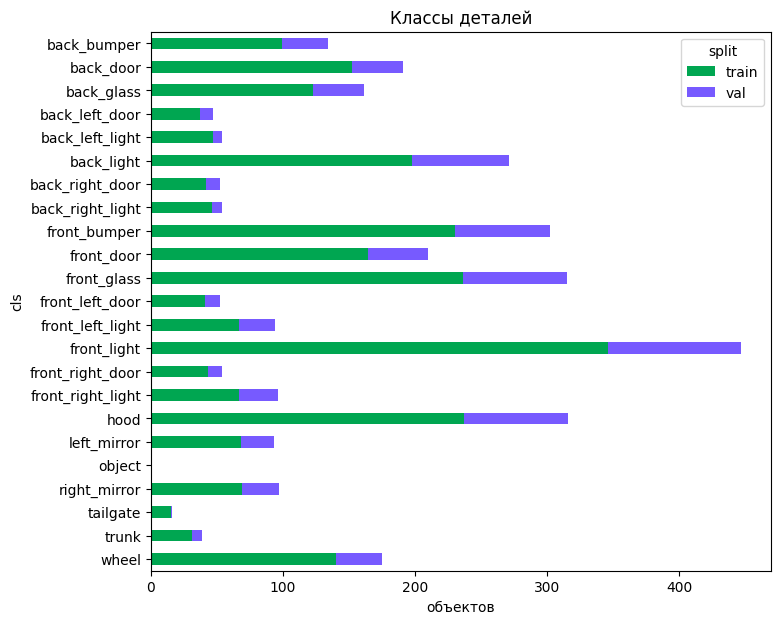

In [5]:
def read_labels(split):
    rows = []
    for f in sorted((CARS / "labels" / split).glob("*.txt")):
        for line in f.read_text().splitlines():
            if line.strip():
                rows.append((split, f.stem, NAMES[int(line.split()[0])]))
    return pd.DataFrame(rows, columns=["split", "image", "cls"])


labels = pd.concat([read_labels("train"), read_labels("val")])
counts = labels.groupby(["cls", "split"]).size().unstack(fill_value=0).loc[NAMES]
print("объектов:", len(labels), "| в среднем на кадр:",
      round(len(labels) / labels.image.nunique(), 1))
counts.plot.barh(figsize=(8, 7), stacked=True, color=["#00A651", "#775AFF"])
plt.xlabel("объектов"); plt.title("Классы деталей"); plt.gca().invert_yaxis(); plt.show()

Классов много, и они неравные: фары и стёкла встречаются в сотне-другой кадров,
класс `object` — считаные разы, на нём модель не научится ничему. Обратите
внимание на пары **`front_left_door` / `front_right_door`**,
**`left_mirror` / `right_mirror`** — к ним вернёмся в разделе 4.

Посмотрим на картинки с разметкой.

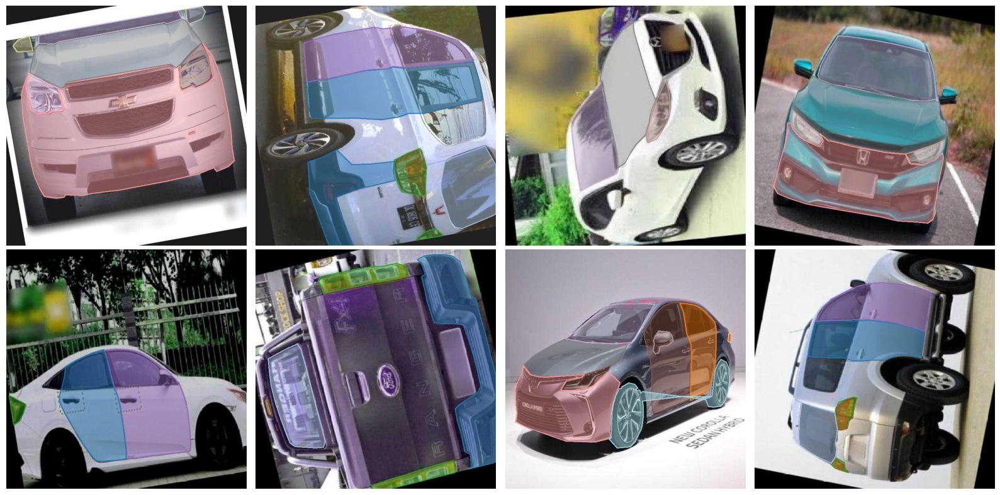

In [6]:
PALETTE = plt.cm.tab20(np.linspace(0, 1, len(NAMES)))[:, :3] * 255


def show_gt(path, ax):
    img = cv2.imread(str(path))[:, :, ::-1].copy()
    h, w = img.shape[:2]
    over = img.copy()
    lbl = CARS / "labels" / path.parent.name / (path.stem + ".txt")
    for line in lbl.read_text().splitlines():
        cls, *xy = line.split()
        poly = (np.array(xy, float).reshape(-1, 2) * [w, h]).astype(np.int32)
        cv2.fillPoly(over, [poly], PALETTE[int(cls)].tolist())
        cv2.polylines(img, [poly], True, PALETTE[int(cls)].tolist(), 2)
    ax.imshow(cv2.addWeighted(img, 0.55, over, 0.45, 0)); ax.axis("off")


val_imgs = sorted((CARS / "images" / "val").glob("*.jpg"))
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, p in zip(axes.flat, val_imgs[::18]):
    show_gt(p, ax)
plt.tight_layout(); plt.show()

### 1.2. Утечка, которую мы вырезали

Оригинальный `carparts-seg` — экспорт с Roboflow, и имена файлов там такие:
`car10_jpg.rf.01c1346d….jpg`, `car10_jpg.rf.291cfe46….jpg`… До `.rf.` стоит имя
**исходного фото**, после — хеш аугментированной копии (поворот, растяжение,
шум). Если посчитать, выходит так:

| | кадров | уникальных исходных фото |
|---|---|---|
| весь датасет | 3833 | **585** |
| валидация | 401 | 295, из них **290 есть и в трейне** |

То есть почти каждое фото из валидации модель уже видела при обучении —
в другой копии, повёрнутое на пару градусов. mAP на таком сплите меряет
запоминание, а не обобщение, и будет красиво завышен.

Поэтому рядом с ноутбуком лежит пересобранная версия: **одна копия на исходное
фото, и делим по исходникам**, 439 кадров в трейн и 146 в валидацию
(функция `build_carparts` выше). Аугментации ultralytics всё равно делает
сам на лету, так что заранее размноженные копии нам не нужны.

📌 **Правило на будущее:** прежде чем учить, проверьте, что одно и то же фото
(снятое подряд, перекодированное, аугментированное) не попало по разные стороны
сплита. Для датасетов из интернета это скорее норма, чем исключение.

---

## 2. Готовая модель за три строки

`YOLO("yolo11n.pt")` скачивает YOLO11 nano, обученную на COCO (80 классов,
среди них `car`, `bus`, `truck`), и сразу готова предсказывать. Буква в имени —
размер: `n` < `s` < `m` < `l` < `x`. Nano — 2,6 млн параметров, работает
даже на процессоре.

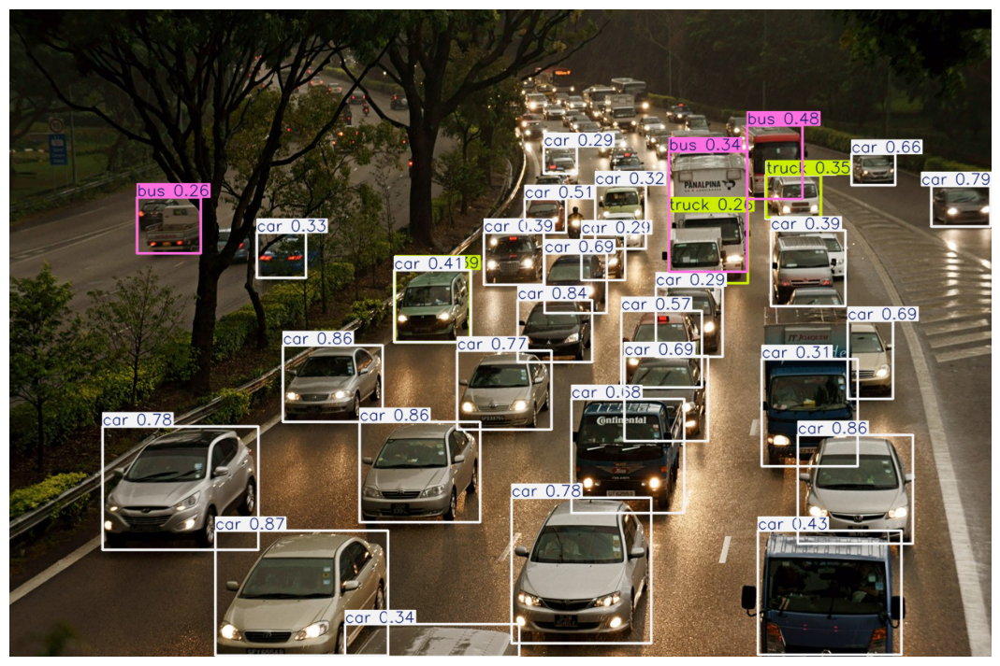

Counter({'car': 28, 'bus': 3, 'truck': 3})


In [7]:
det = YOLO("yolo11n.pt")
res = det(STREET / "jam.jpg", verbose=False)[0]

plt.figure(figsize=(14, 9)); plt.imshow(res.plot(line_width=2)[:, :, ::-1]); plt.axis("off"); plt.show()
print(collections.Counter(res.names[int(c)] for c in res.boxes.cls))

Результат — объект `Results`. Всё, что нужно дальше, лежит в `res.boxes`:

In [8]:
b = res.boxes
print("рамки xyxy:", tuple(b.xyxy.shape), "| уверенность:", tuple(b.conf.shape), "| класс:", tuple(b.cls.shape))
print("время, мс:", {k: round(v, 1) for k, v in res.speed.items()})
for xyxy, conf, cls in list(zip(b.xyxy, b.conf, b.cls))[:3]:
    print(f"{res.names[int(cls)]:>6} {conf:.2f}  {xyxy.round().int().tolist()}")

рамки xyxy: (34, 4) | уверенность: (34,) | класс: (34,)
время, мс: {'preprocess': 54.5, 'inference': 15.3, 'postprocess': 21.1}
   car 0.87  [269, 680, 494, 843]
   car 0.86  [1028, 555, 1177, 698]
   car 0.86  [456, 538, 613, 669]


Тот же `Results` возвращают сегментация (`res.masks`), поза (`res.keypoints`),
классификация (`res.probs`) — интерфейс у всех задач общий.

---

## 3. NMS: что прячется за `det(...)`

`det(...)` — это три шага: подготовка картинки, прогон сети и постобработка.
Постобработка — это NMS, тот самый жадный алгоритм с лекции. Разберём её
по шагам на сыром выходе сети.

### 3.1. Сырой выход: 8400 кандидатов

Картинку приводим к 640×640 **с сохранением пропорций**: уменьшаем и добиваем
серыми полосами (letterbox). Так делает сама ultralytics — повторяем за ней.

In [ ]:
def letterbox(img, size=640):
    """Уменьшить с сохранением пропорций и добить серым до size×size."""
    h, w = img.shape[:2]
    gain = min(size / h, size / w)
    nh, nw = round(h * gain), round(w * gain)
    top, left = (size - nh) // 2, (size - nw) // 2
    out = np.full((size, size, 3), 114, np.uint8)
    out[top:top + nh, left:left + nw] = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    return out, gain, (left, top)


def to_tensor(img):
    """BGR uint8 HxWx3 → RGB float 1x3xHxW в [0, 1]."""
    return torch.from_numpy(img[:, :, ::-1].copy()).permute(2, 0, 1)[None].float() / 255


img = cv2.imread(str(STREET / "jam.jpg"))
lb, gain, (left, top) = letterbox(img)
net = copy.deepcopy(det.model).float().eval().cpu()   # копия: сама det остаётся на своём устройстве
with torch.no_grad():
    raw = net(t»o_tensor(lb))[0][0]

print("исходный кадр:", img.shape[:2], "→ вход сети:", lb.shape[:2])
print("сырой выход:", tuple(raw.shape))

исходный кадр: (845, 1280) → вход сети: (640, 640)
сырой выход: (84, 8400)


Выход — **84 × 8400**. 8400 — это все точки трёх карт признаков:
80×80 (шаг 8 пикселей) + 40×40 (шаг 16) + 20×20 (шаг 32) = 6400 + 1600 + 400.
В каждой точке сеть выдаёт рамку (первые 4 числа: центр и размеры
в пикселях входа 640×640) и 80 вероятностей классов COCO. Отдельного
«objectness», как в YOLOv3, у YOLO11 нет: уверенность рамки — это максимум
по классам.

In [10]:
boxes_cxcywh, scores_all = raw[:4].T, raw[4:].T
conf, cls = scores_all.max(1)

for thr in (0.01, 0.1, 0.25, 0.5):
    print(f"уверенность > {thr:<4}: {(conf > thr).sum().item():5d} кандидатов")


def to_xyxy_orig(cxcywh):
    """(cx, cy, w, h) во входе сети → (x1, y1, x2, y2) в пикселях исходного кадра."""
    xyxy = torchvision.ops.box_convert(cxcywh, "cxcywh", "xyxy")
    xyxy[:, [0, 2]] -= left
    xyxy[:, [1, 3]] -= top
    return xyxy / gain


keep = conf > 0.25
cand_boxes, cand_conf, cand_cls = to_xyxy_orig(boxes_cxcywh[keep]), conf[keep], cls[keep]

уверенность > 0.01:   671 кандидатов
уверенность > 0.1 :   363 кандидатов
уверенность > 0.25:   233 кандидатов
уверенность > 0.5 :   122 кандидатов


### 3.2. NMS своими руками

Порог уверенности 0.25 (дефолт ultralytics) оставляет пару сотен кандидатов,
а машин на фото десятка три: соседние точки карты признаков видят одну и ту же
машину и выдают почти одинаковые рамки. NMS оставляет из каждой такой пачки
одну — самую уверенную:

1. берём самую уверенную рамку, кладём в ответ;
2. выкидываем все рамки, у которых IoU с ней больше порога;
3. повторяем, пока кандидаты не кончатся.

NMS делается **для каждого класса отдельно** (машина не должна гасить
перекрывающий её автобус). Стандартный трюк: сдвинуть рамки каждого класса
на своё большое смещение — тогда рамки разных классов не пересекаются никогда,
и хватает одного прохода.

In [11]:
def nms(boxes, scores, iou_thr):
    order = scores.argsort(descending=True)
    keep = []
    while order.numel() > 0:
        best = order[0]
        keep.append(best.item())
        iou = torchvision.ops.box_iou(boxes[best][None], boxes[order[1:]])[0]
        order = order[1:][iou <= iou_thr]
    return torch.tensor(keep, dtype=torch.long)


def nms_per_class(boxes, scores, classes, iou_thr):
    offset = classes[:, None].float() * 10_000     # рамки разных классов разнесены далеко
    return nms(boxes + offset, scores, iou_thr)


kept = nms_per_class(cand_boxes, cand_conf, cand_cls, 0.7)
ref = torchvision.ops.batched_nms(cand_boxes, cand_conf, cand_cls, 0.7)
print(f"кандидатов: {len(cand_boxes)} → после NMS: {len(kept)}")
print("совпадает с torchvision.ops.batched_nms:", sorted(kept.tolist()) == sorted(ref.tolist()))
print("сколько рамок у ultralytics:", len(res.boxes))

кандидатов: 233 → после NMS: 33
совпадает с torchvision.ops.batched_nms: True
сколько рамок у ultralytics: 34


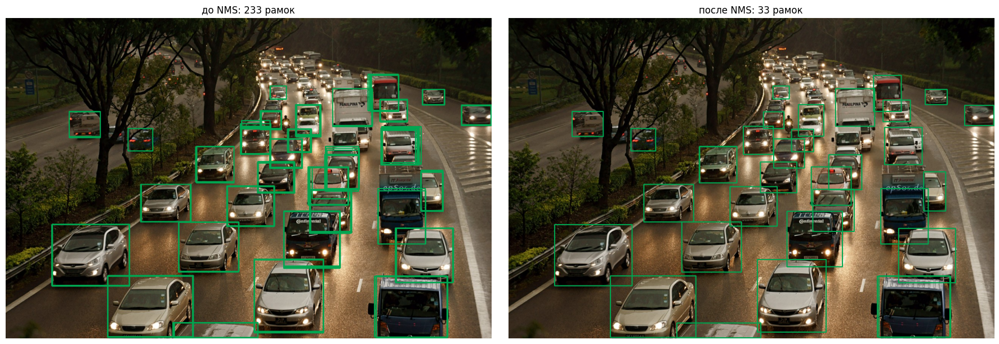

In [12]:
def draw_boxes(img, boxes, ax, title, color=(0, 166, 81)):
    out = img[:, :, ::-1].copy()
    for x1, y1, x2, y2 in boxes.round().int().tolist():
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)
    ax.imshow(out); ax.set_title(title); ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(18, 6))
draw_boxes(img, cand_boxes, axes[0], f"до NMS: {len(cand_boxes)} рамок")
draw_boxes(img, cand_boxes[kept], axes[1], f"после NMS: {len(kept)} рамок")
plt.tight_layout(); plt.show()

### 3.3. Порог IoU на картинке

В ultralytics порог NMS — аргумент `iou` (по умолчанию 0.7). Прогоним три фото
с разными порогами. Маленький порог — агрессивное подавление, порог около 1 —
NMS фактически выключен.

In [13]:
IOUS = (0.3, 0.5, 0.7, 0.9, 0.99)
table = {f: [len(det(STREET / f, iou=t, verbose=False)[0].boxes) for t in IOUS]
         for f in ("jam.jpg", "taxi.jpg", "lisbon.jpg")}
pd.DataFrame(table, index=[f"iou={t}" for t in IOUS]).T

,iou=0.3,iou=0.5,iou=0.7,iou=0.9,iou=0.99
jam.jpg,34,34,34,39,162
taxi.jpg,12,12,14,20,76
lisbon.jpg,16,16,16,24,71


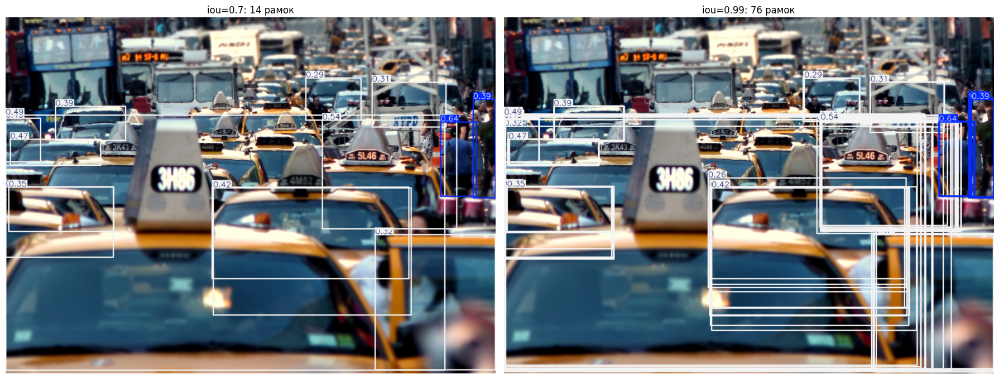

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, t in zip(axes, (0.7, 0.99)):
    r = det(STREET / "taxi.jpg", iou=t, verbose=False)[0]
    ax.imshow(r.plot(labels=False, line_width=2)[:, :, ::-1]); ax.set_title(f"iou={t}: {len(r.boxes)} рамок"); ax.axis("off")
plt.tight_layout(); plt.show()

Итог по картинкам:

* **от 0.3 до 0.7 картина почти не меняется** — на `jam.jpg` и `lisbon.jpg`
  число рамок одинаковое. Рамки соседних машин перекрываются слабо,
  им нечего подавлять друг друга;
* **при 0.9 появляются дубли**, а при 0.99 NMS фактически выключен,
  и рамок становится в 4–5 раз больше, чем машин.

Где NMS действительно режет лишнее — в толпе: плотно стоящие объекты
перекрываются сильно, и низкий порог начинает гасить **настоящих соседей**.
Это его известная слабость, мы видели её на лекции.

### 3.4. Модель без NMS: YOLO26

В новых YOLO (YOLOv10, YOLO26) есть вторая голова, обученная
**один объект → одно предсказание** (one-to-one), как в DETR. Её выходу NMS
не нужен. ⚠️ Но в ultralytics 8.4 **по умолчанию и YOLO26 идёт через NMS**
(голова one-to-many — у неё точнее рамки). Чтобы включить режим без NMS,
надо явно передать `nms=False`.

In [15]:
det26 = YOLO("yolo26n.pt")
rows = {}
for mode in (None, False):
    rows[f"nms={mode}"] = [len(det26(STREET / "jam.jpg", iou=t, nms=mode, verbose=False)[0].boxes) for t in IOUS]
pd.DataFrame(rows, index=[f"iou={t}" for t in IOUS]).T

,iou=0.3,iou=0.5,iou=0.7,iou=0.9,iou=0.99
nms=None,24,24,24,24,108
nms=False,21,21,21,21,21


С `nms=False` порог `iou` перестаёт на что-то влиять: число рамок одно
и то же. Зачем это нужно, если NMS и так быстрый? На сервере с видеокартой —
почти незачем. А на телефонах, NPU и в TensorRT NMS неудобен: он
последовательный, число рамок на выходе заранее не известно, и его приходится
писать отдельно под каждую платформу. Сеть без NMS экспортируется одним куском.

---

## 4. Дообучение детектора на своих данных

Главное, ради чего берут ultralytics, — дообучение в одну строку. Возьмём
YOLO11n с весами COCO и дообучим на деталях машин. Сначала — **со всеми
настройками по умолчанию**, как сделал бы любой, кто видит библиотеку впервые.

Функция ниже — тонкая обёртка над `model.train`: она прячет длинный лог
ultralytics и печатает mAP раз в 5 эпох через **колбэк**. Колбэки — штатный
способ встроиться в цикл обучения: залогировать метрику, остановить обучение,
сохранить картинку.

In [16]:
RUNS = Path("runs").resolve()


def train(name, weights="yolo11n.pt", **overrides):
    model = YOLO(weights)

    def report(trainer):
        e = trainer.epoch + 1
        if e % 5 == 0 or e == trainer.epochs:
            key = "metrics/mAP50(M)" if "metrics/mAP50(M)" in trainer.metrics else "metrics/mAP50(B)"
            print(f"  эпоха {e:3d}: mAP50 = {trainer.metrics[key]:.3f}", flush=True)

    model.add_callback("on_fit_epoch_end", report)
    level = LOGGER.level
    LOGGER.setLevel(logging.WARNING)                 # без построчного лога ultralytics
    t = time.time()
    try:
        model.train(data=str(YAML), epochs=EPOCHS, imgsz=640, batch=16, seed=0, device=DEVICE,
                    workers=2, project=str(RUNS), name=name, exist_ok=True, plots=False, **overrides)
    finally:
        LOGGER.setLevel(level)
    print(f"{name}: {time.time() - t:.0f} с")
    return YOLO(RUNS / name / "weights" / "best.pt")


def evaluate(model, **kw):
    LOGGER.setLevel(logging.WARNING)
    try:
        return model.val(data=str(YAML), device=DEVICE, plots=False, verbose=False, **kw)
    finally:
        LOGGER.setLevel(logging.INFO)

In [17]:
det_default = train("det_default")

  эпоха   5: mAP50 = 0.163


  эпоха  10: mAP50 = 0.279


  эпоха  15: mAP50 = 0.385


  эпоха  20: mAP50 = 0.467


  эпоха  25: mAP50 = 0.456


  эпоха  30: mAP50 = 0.519


  эпоха  35: mAP50 = 0.517


  эпоха  40: mAP50 = 0.546


det_default: 249 с


Кривые обучения ultralytics пишет в `runs/<имя>/results.csv` — это обычная
таблица, её удобно читать pandas.

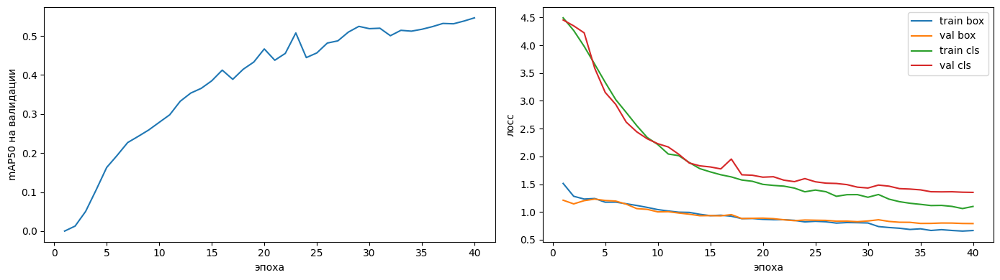

In [18]:
def curves(name, ax=None, key="metrics/mAP50(B)", label=None):
    d = pd.read_csv(RUNS / name / "results.csv")
    d.columns = [c.strip() for c in d.columns]
    (ax or plt.gca()).plot(d["epoch"], d[key], label=label or name)
    return d


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
d = curves("det_default", axes[0])
axes[0].set_xlabel("эпоха"); axes[0].set_ylabel("mAP50 на валидации")
axes[1].plot(d["epoch"], d["train/box_loss"], label="train box")
axes[1].plot(d["epoch"], d["val/box_loss"], label="val box")
axes[1].plot(d["epoch"], d["train/cls_loss"], label="train cls")
axes[1].plot(d["epoch"], d["val/cls_loss"], label="val cls")
axes[1].set_xlabel("эпоха"); axes[1].set_ylabel("лосс"); axes[1].legend()
plt.tight_layout(); plt.show()

In [19]:
def per_class(metrics):
    return pd.Series({NAMES[c]: metrics.box.ap50[i] for i, c in enumerate(metrics.box.ap_class_index)})


m_default = evaluate(det_default)
print(f"mAP50 = {m_default.box.map50:.3f}, mAP50-95 = {m_default.box.map:.3f}")
ap_default = per_class(m_default)
is_lr = ap_default.index.str.contains("left|right")
print(f"AP50 деталей с «left/right» в имени: {ap_default[is_lr].mean():.3f}")
print(f"AP50 остальных деталей:             {ap_default[~is_lr].mean():.3f}")

mAP50 = 0.547, mAP50-95 = 0.419
AP50 деталей с «left/right» в имени: 0.439
AP50 остальных деталей:             0.629


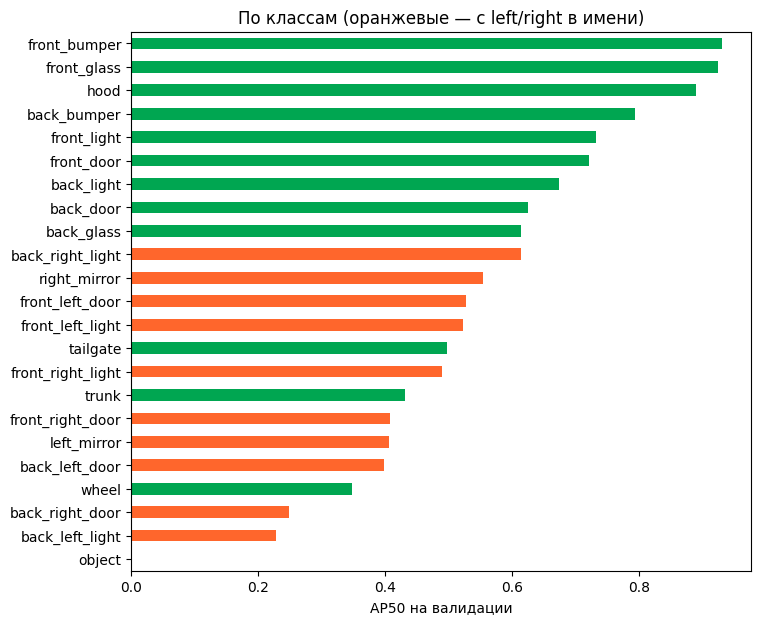

In [20]:
s = ap_default.sort_values()
ax = s.plot.barh(figsize=(8, 7), color=np.where(s.index.str.contains("left|right"), "#FF662C", "#00A651"))
ax.set_xlabel("AP50 на валидации"); ax.set_title("По классам (оранжевые — с left/right в имени)"); plt.show()

**Стоп. Почему оранжевые классы так проседают?** Двери, фары, зеркала
с «left»/«right» в имени учатся заметно хуже симметричных деталей — капота,
бампера, лобового стекла. Сами по себе они ничем не сложнее: левая фара
выглядит как правая.

Подумайте минуту, прежде чем читать дальше. Подсказка: что ultralytics
делает с картинками во время обучения?

…

Ответ — **аугментация `fliplr=0.5`**: по умолчанию каждая вторая картинка
отражается по горизонтали. Для COCO это безобидно: отражённая машина всё равно
машина. А у нас отражённая **левая** дверь становится **правой**, но метка
остаётся «левая». Половину эпох модель учат, что левое — это правое.

Аугментация — не «бесплатное улучшение», а утверждение о задаче:
«ответ не меняется при таком преобразовании». Здесь это утверждение ложно.

---

## 5. Гиперпараметры

Все настройки ultralytics — это аргументы `train` / `predict` / `val`.
Полный список — `ultralytics/cfg/default.yaml` (около сотни). На практике
трогают дюжину:

| группа | параметр | по умолчанию | что делает |
|---|---|---|---|
| обучение | `epochs` | 100 | число эпох |
| | `imgsz` | 640 | размер входа; мелкие объекты → больше |
| | `batch` | 16 | размер батча; `-1` — подобрать под память |
| | `optimizer`, `lr0` | `auto`, 0.01 | оптимизатор и темп; `auto` сам выбирает SGD/AdamW и lr |
| | `patience` | 100 | ранняя остановка, если метрика не растёт N эпох |
| | `freeze` | — | заморозить первые N слоёв (бэкбон) |
| | `pretrained` | True | стартовать с весов COCO |
| аугментации | `fliplr` | 0.5 | вероятность отражения по горизонтали |
| | `mosaic` | 1.0 | склейка 4 картинок в одну; `close_mosaic=10` выключает её в конце |
| | `hsv_h/s/v`, `degrees`, `scale`, `translate` | … | цвет и геометрия |
| инференс | `conf` | 0.25 (val: 0.001) | порог уверенности |
| | `iou` | 0.7 | порог NMS |
| | `max_det` | 300 | максимум рамок на кадр |
| | `classes`, `agnostic_nms` | — | фильтр классов; NMS без учёта классов |

Ultralytics умеет и **сам подбирать гиперпараметры**: `model.tune(...)` —
генетический поиск, но это десятки обучений, на семинаре не запускаем.

### 5.1. Чиним `fliplr`

In [21]:
det_ft = train("det", fliplr=0.0)
m_ft = evaluate(det_ft)
ap_ft = per_class(m_ft)
print(f"mAP50: {m_default.box.map50:.3f} → {m_ft.box.map50:.3f}")
print(f"left/right: {ap_default[is_lr].mean():.3f} → {ap_ft[is_lr].mean():.3f}")
print(f"остальные:  {ap_default[~is_lr].mean():.3f} → {ap_ft[~is_lr].mean():.3f}")

  эпоха   5: mAP50 = 0.164


  эпоха  10: mAP50 = 0.313


  эпоха  15: mAP50 = 0.475


  эпоха  20: mAP50 = 0.534


  эпоха  25: mAP50 = 0.585


  эпоха  30: mAP50 = 0.625


  эпоха  35: mAP50 = 0.662


  эпоха  40: mAP50 = 0.675


det: 276 с


mAP50: 0.547 → 0.675
left/right: 0.439 → 0.736
остальные:  0.629 → 0.628


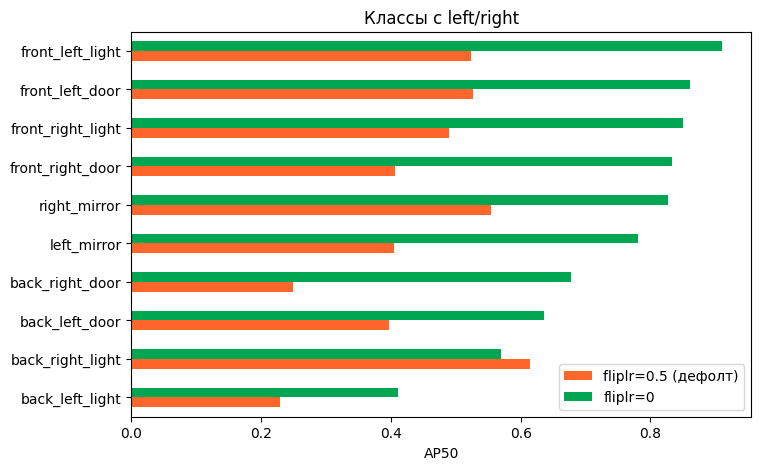

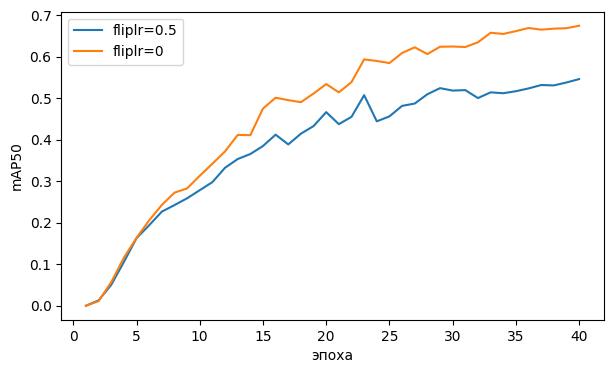

In [22]:
cmp = pd.DataFrame({"fliplr=0.5 (дефолт)": ap_default, "fliplr=0": ap_ft})
cmp = cmp.loc[cmp.index.str.contains("left|right")].sort_values("fliplr=0")
cmp.plot.barh(figsize=(8, 5), color=["#FF662C", "#00A651"])
plt.xlabel("AP50"); plt.title("Классы с left/right"); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
curves("det_default", ax, label="fliplr=0.5"); curves("det", ax, label="fliplr=0")
ax.set_xlabel("эпоха"); ax.set_ylabel("mAP50"); ax.legend(); plt.show()

Одна строчка — и mAP50 вырос на 14 пунктов, причём почти целиком за счёт
классов с «left/right». Симметричным деталям отражение не мешало.

**Сколько стоят остальные ручки.** Мы замерили их заранее на той же машине
(V100, 40 эпох, `fliplr=0`), чтобы не тратить время семинара:

| прогон | mAP50 | mAP50-95 | время |
|---|---|---|---|
| дообучение, `fliplr=0` (сид 0 / сид 1) | 0.72 / 0.69 | 0.54 / 0.52 | 4 мин |
| то же с `fliplr=0.5` (сид 0 / сид 1) | 0.58 / 0.55 | 0.45 / 0.43 | 4 мин |
| `freeze=10` — бэкбон заморожен | 0.57 | 0.44 | 3 мин |
| `yolo11n.yaml` — с нуля, без весов COCO | **0.08** | 0.03 | 4 мин |
| 80 эпох вместо 40 | 0.77 | 0.60 | 8 мин |

Что из этого следует:

* **Разброс между сидами — около 3 пунктов.** Разница меньше этого на одном
  прогоне ничего не доказывает. Отрыв `fliplr` (13–14 пунктов на обоих сидах)
  — доказывает.
* **Предобучение решает всё:** с нуля на 439 картинках за 40 эпох сеть
  не учится почти ничему. Это transfer learning из лекции 3 в цифрах.
* **Заморозка бэкбона** экономит четверть времени, но стоит 15 пунктов:
  признаки COCO про «машину целиком», а нам нужны детали.
* **40 эпох — мало**, кривая ещё растёт. Мы остановились на 40 из-за времени
  семинара.

### 5.2. NMS и метрика

В разделе 3 порог NMS меняли на картинке. Теперь измерим, что он делает
с mAP на валидации: прогоним `val` дообученной модели с разными `iou`.

In [23]:
nms_rows = []
for t in (0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99):
    m = evaluate(det_ft, iou=t)
    nms_rows.append({"iou": t, "mAP50": m.box.map50, "mAP50-95": m.box.map,
                     "precision": m.box.mp, "recall": m.box.mr})
nms_table = pd.DataFrame(nms_rows).set_index("iou").round(3)
nms_table

,mAP50,mAP50-95,precision,recall
iou,,,,
0.30,0.681,0.517,0.660,0.661
0.50,0.680,0.518,0.653,0.656
0.60,0.679,0.519,0.650,0.654
0.70,0.675,0.521,0.644,0.655
0.80,0.667,0.520,0.634,0.651
0.90,0.644,0.508,0.623,0.606
0.95,0.583,0.468,0.558,0.586
0.99,0.364,0.297,0.399,0.394


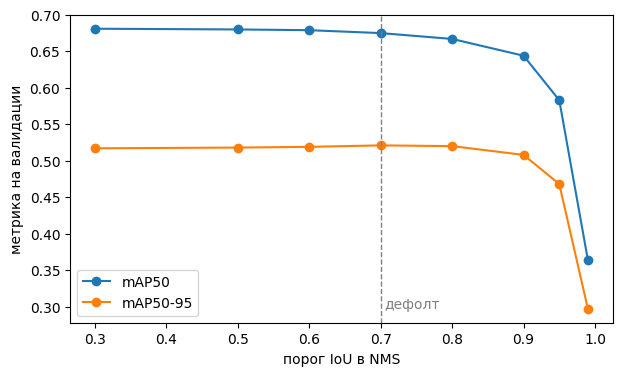

In [24]:
ax = nms_table[["mAP50", "mAP50-95"]].plot(marker="o", figsize=(7, 4))
ax.axvline(0.7, color="gray", ls="--", lw=1); ax.text(0.705, ax.get_ylim()[0] + 0.02, "дефолт", color="gray")
ax.set_xlabel("порог IoU в NMS"); ax.set_ylabel("метрика на валидации"); plt.show()

* **Плато от 0.3 до 0.8:** mAP меняется меньше чем на пункт. Дефолт 0.7
  стоит на этом плато — трогать его без причины незачем.
* **Выше 0.9 метрика падает**, при 0.99 — почти вдвое. Дубли одной и той же
  детали засчитываются как ложные срабатывания, и precision проваливается
  на всех порогах уверенности.

Выходит, что NMS нужен обязательно, а точное значение порога почти
не важно — пока он не близок к единице.

### 5.3. Как выглядят предсказания

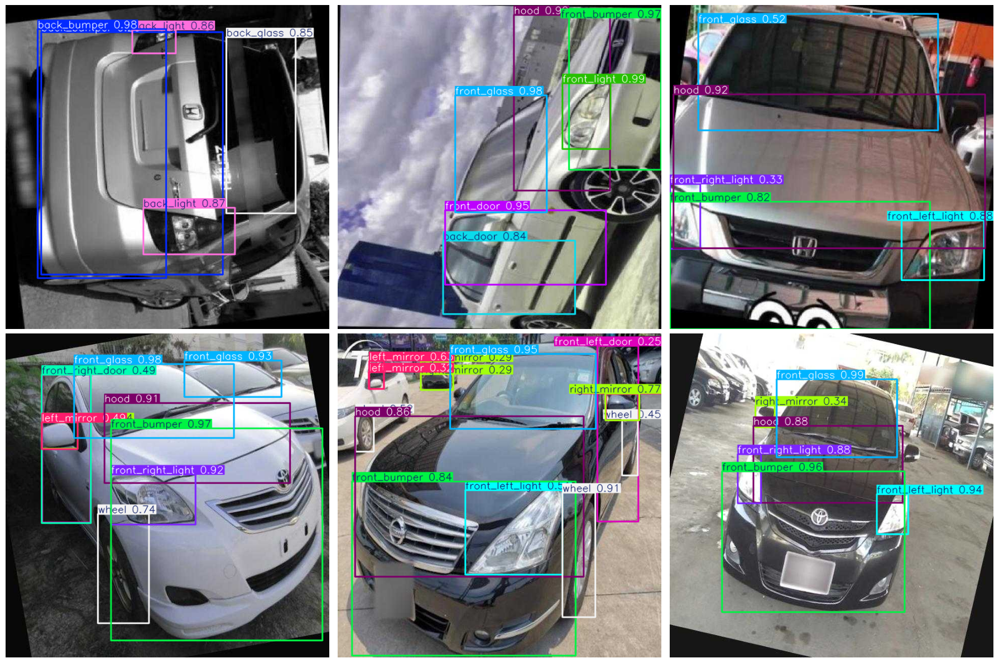

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, p in zip(axes.flat, val_imgs[3::25]):
    r = det_ft(p, verbose=False)[0]
    ax.imshow(r.plot(line_width=2, font_size=10)[:, :, ::-1]); ax.axis("off")
plt.tight_layout(); plt.show()

---

## 6. Сегментация экземпляров

Для сегментации меняется одна буква: веса `yolo11n-seg.pt`. Голова
сегментации — в духе Mask R-CNN из лекции, только одностадийная: сеть
предсказывает набор общих «прототипов» масок на весь кадр и для каждой рамки
коэффициенты, с которыми их смешать. Данные те же, полигоны из разметки
теперь используются по назначению.

In [26]:
seg_ft = train("seg", "yolo11n-seg.pt", fliplr=0.0)
m_seg = evaluate(seg_ft)
print(f"рамки: mAP50 = {m_seg.box.map50:.3f}, mAP50-95 = {m_seg.box.map:.3f}")
print(f"маски: mAP50 = {m_seg.seg.map50:.3f}, mAP50-95 = {m_seg.seg.map:.3f}")

  эпоха   5: mAP50 = 0.173


  эпоха  10: mAP50 = 0.358


  эпоха  15: mAP50 = 0.501


  эпоха  20: mAP50 = 0.542


  эпоха  25: mAP50 = 0.607


  эпоха  30: mAP50 = 0.643


  эпоха  35: mAP50 = 0.660


  эпоха  40: mAP50 = 0.673


seg: 389 с


рамки: mAP50 = 0.679, mAP50-95 = 0.524
маски: mAP50 = 0.680, mAP50-95 = 0.500


У сегментации **две** метрики: mAP по рамкам и mAP по маскам (IoU считается
между масками, а не между рамками). При пороге 0.5 они почти равны,
а на строгих порогах (mAP50-95) маски отстают: попасть маской пиксель
в пиксель труднее, чем рамкой.

Маски лежат в `res.masks`: растром (`.data`) и полигонами (`.xy`).

маски: (4, 640, 640) | полигон первой маски: (223, 2) вершин × (x, y)


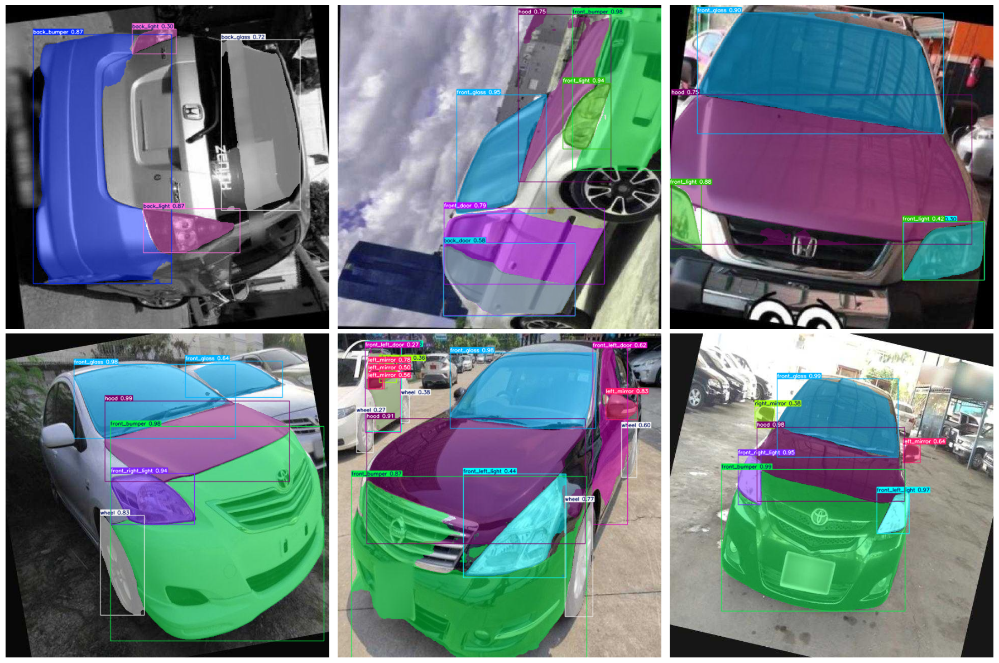

In [27]:
r = seg_ft(val_imgs[40], verbose=False)[0]
print("маски:", tuple(r.masks.data.shape), "| полигон первой маски:", r.masks.xy[0].shape, "вершин × (x, y)")

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, p in zip(axes.flat, val_imgs[3::25]):
    ax.imshow(seg_ft(p, verbose=False)[0].plot(line_width=1, font_size=10)[:, :, ::-1]); ax.axis("off")
plt.tight_layout(); plt.show()

---

## 7. SAM2 в ultralytics

**SAM** (Segment Anything, Meta) — модель, которая сегментирует **что угодно
по подсказке**: рамке, точке или маске. Классов она не знает: она отвечает
на вопрос «где граница объекта, на который мне показали», а не «что это».
**SAM2** — вторая версия, быстрее и умеет видео. В ultralytics она
загружается так же, как YOLO: `SAM("sam2.1_t.pt")` (tiny, 39 МБ;
есть `_s`, `_b`, `_l`).

Самая практичная связка — **детектор + SAM**: детектор даёт рамки и классы,
SAM превращает рамки в маски. Сегментационную модель для этого учить не нужно.

рамок от детектора: 8, масок от SAM2: 8, 0.2 с


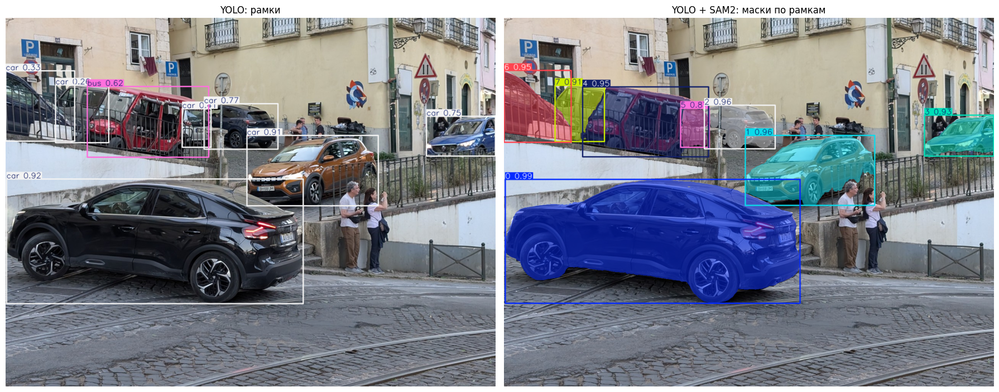

In [28]:
sam = SAM("sam2.1_t.pt")
path = STREET / "lisbon.jpg"
cars = det(path, classes=[2, 5, 7], verbose=False)[0]      # car, bus, truck из COCO
t = time.time()
masks = sam(path, bboxes=cars.boxes.xyxy.tolist(), verbose=False)[0]
print(f"рамок от детектора: {len(cars.boxes)}, масок от SAM2: {len(masks.masks)}, {time.time() - t:.1f} с")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].imshow(cars.plot(line_width=2)[:, :, ::-1]); axes[0].set_title("YOLO: рамки")
axes[1].imshow(masks.plot(line_width=2)[:, :, ::-1]); axes[1].set_title("YOLO + SAM2: маски по рамкам")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

Подсказкой может быть и **точка**: метка `1` — «объект здесь», `0` — «это фон».
Одна точка неоднозначна: щелчок по двери может означать и дверь, и машину
целиком. Уточняют её ещё парой щелчков — так и работают интерфейсы разметки
на SAM.

⚠️ **Подвох API:** чтобы несколько точек описывали **один** объект, их передают
вложенным списком: `points=[[[x1, y1], [x2, y2]]]`, `labels=[[1, 0]]`.
Плоский список `[[x1, y1], [x2, y2]]` ultralytics читает как отдельные
подсказки для разных объектов.

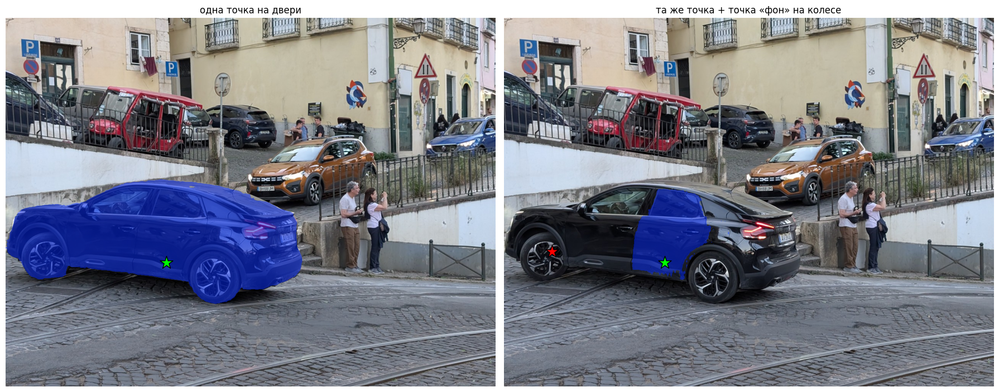

In [29]:
PROMPTS = [
    ("одна точка на двери", [[420, 640]], [1]),
    ("та же точка + точка «фон» на колесе", [[[420, 640], [125, 610]]], [[1, 0]]),
]
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (title, points, labels) in zip(axes, PROMPTS):
    r = sam(path, points=points, labels=labels, verbose=False)[0]
    ax.imshow(r.plot(boxes=False)[:, :, ::-1]); ax.set_title(title); ax.axis("off")
    for (x, y), lab in zip(np.reshape(points, (-1, 2)), np.ravel(labels)):
        ax.scatter(x, y, s=300, c="lime" if lab else "red", marker="*", edgecolors="k")
plt.tight_layout(); plt.show()

### 7.1. Насколько SAM2 хорош как разметчик

Разметить рамку — секунды, обвести полигон — минута. Если SAM по рамке
выдаёт маску не хуже ручной, разметку сегментации можно заменить разметкой
рамок. Проверим на нашей валидации: дадим SAM2 **идеальные рамки** из разметки
и сравним его маски с ручными полигонами. Для сравнения — «маска», которая
просто заливает рамку целиком.

In [30]:
def gt_instances(path):
    img = cv2.imread(str(path))
    h, w = img.shape[:2]
    out = []
    for line in (CARS / "labels" / "val" / (path.stem + ".txt")).read_text().splitlines():
        cls, *xy = line.split()
        poly = (np.array(xy, float).reshape(-1, 2) * [w, h]).astype(np.int32)
        m = np.zeros((h, w), np.uint8)
        cv2.fillPoly(m, [poly], 1)
        x1, y1 = poly.min(0); x2, y2 = poly.max(0)
        out.append((NAMES[int(cls)], m.astype(bool), [float(x1), float(y1), float(x2), float(y2)]))
    return img, out


def mask_iou(a, b):
    return (a & b).sum() / max((a | b).sum(), 1)


rows = []
t = time.time()
for p in val_imgs:
    img, inst = gt_instances(p)
    if not inst:
        continue
    pred = sam(img, bboxes=[b for _, _, b in inst], verbose=False)[0].masks.data.cpu().numpy() > 0.5
    for (name, gt, (x1, y1, x2, y2)), pm in zip(inst, pred):
        box_mask = np.zeros_like(gt)
        box_mask[int(y1):int(y2) + 1, int(x1):int(x2) + 1] = True
        rows.append({"cls": name, "sam": mask_iou(gt, pm), "box": mask_iou(gt, box_mask)})
sam_iou = pd.DataFrame(rows)
print(f"{len(sam_iou)} объектов, {time.time() - t:.0f} с")
print(sam_iou[["sam", "box"]].describe().loc[["mean", "50%"]].round(3))
print(f"доля масок SAM2 с IoU > 0.8: {(sam_iou.sam > 0.8).mean():.2f}")

763 объектов, 20 с
        sam    box
mean  0.807  0.632
50%   0.862  0.641
доля масок SAM2 с IoU > 0.8: 0.70


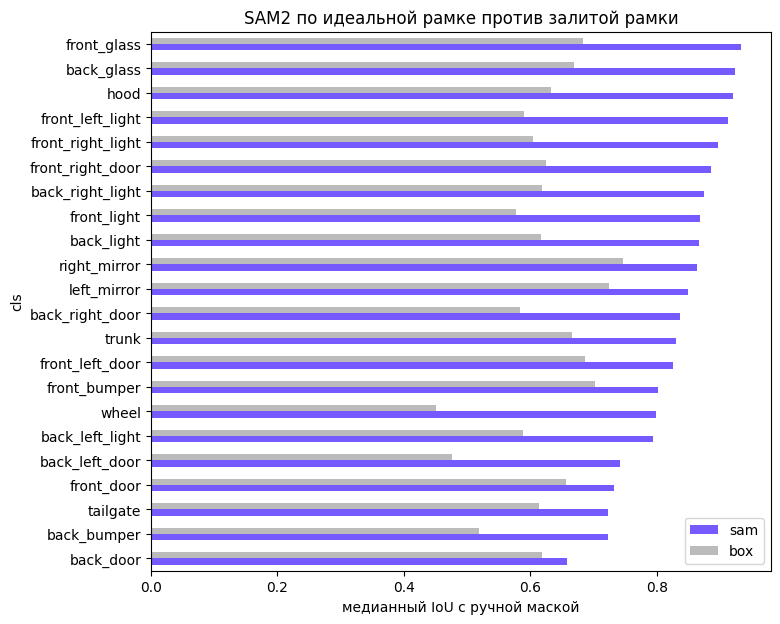

In [31]:
by_cls = sam_iou.groupby("cls")[["sam", "box"]].median().sort_values("sam")
by_cls.plot.barh(figsize=(8, 7), color=["#775AFF", "#BBBBBB"])
plt.xlabel("медианный IoU с ручной маской"); plt.title("SAM2 по идеальной рамке против залитой рамки"); plt.show()

По медиане SAM2 даёт маску с IoU около 0.8 против ручной — заметно лучше
залитой рамки. Но **среднее ниже медианы**: есть хвост провалов.
По классам видно, где именно: плоские детали без чёткой границы (двери, у
которых соседняя дверь того же цвета, бамперы) SAM путает, а колёса, фары
и стёкла с контрастным краем обводит хорошо.

Практический вывод: **SAM2 — отличный черновик разметки**, который человек
поправляет, а не готовая разметка.

### 7.2. Автоматическая разметка

В ultralytics связка «детектор → SAM» уже завёрнута в одну функцию:
`auto_annotate` проходит по папке с картинками и пишет в `labels/`
полигоны в формате YOLO — готовые данные для обучения `-seg`-модели.
Запустим её на пяти картинках с нашим дообученным детектором.

In [32]:
from ultralytics.data.annotator import auto_annotate

demo = Path("auto_demo")
shutil.rmtree(demo, ignore_errors=True); (demo / "images").mkdir(parents=True)
for p in val_imgs[:5]:
    shutil.copy(p, demo / "images")
auto_annotate(data=demo / "images", det_model=str(RUNS / "det" / "weights" / "best.pt"),
              sam_model="sam2.1_t.pt", device=DEVICE, output_dir=demo / "labels")
f = sorted((demo / "labels").glob("*.txt"))[0]
lines = f.read_text().splitlines()
print(f"{f.name}: {len(lines)} объектов, первая строка: {lines[0][:90]}...")

image 1/5 /home/vkborisov16/projects/lectures/sirius/seminar5/nb_run/auto_demo/images/car125_jpg.jpg: 640x640 1 front_bumper, 1 front_left_light, 1 front_right_light, 1 hood, 14.9ms


image 2/5 /home/vkborisov16/projects/lectures/sirius/seminar5/nb_run/auto_demo/images/car142_jpg.jpg: 640x640 1 front_bumper, 1 front_glass, 2 front_lights, 1 hood, 15.3ms


image 3/5 /home/vkborisov16/projects/lectures/sirius/seminar5/nb_run/auto_demo/images/car25_jpg.jpg: 640x640 1 back_bumper, 1 back_glass, 2 back_lights, 15.5ms


image 4/5 /home/vkborisov16/projects/lectures/sirius/seminar5/nb_run/auto_demo/images/car88_jpg.jpg: 640x640 1 back_bumper, 1 back_glass, 2 back_lights, 15.6ms


image 5/5 /home/vkborisov16/projects/lectures/sirius/seminar5/nb_run/auto_demo/images/new_15_png_jpg.jpg: 640x640 1 back_bumper, 2 back_doors, 1 back_glass, 2 back_lights, 1 front_door, 1 trunk, 15.9ms


Speed: 1.0ms preprocess, 15.4ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 640)


car125_jpg.txt: 4 объектов, первая строка: 12 0.7984374761581421 0.17031249403953552 0.7984374761581421 0.17343750596046448 0.796875 ...


---

## 8. Что ещё умеет ultralytics

Всё ниже устроено так же: `YOLO("<веса>")`, потом `.predict / .train / .val /
.export`. Меняются веса и формат разметки.

| задача | веса | что на выходе |
|---|---|---|
| детекция | `yolo11n.pt`, `yolo26n.pt` | рамки + классы |
| сегментация экземпляров | `yolo11n-seg.pt` | маски объектов |
| классификация | `yolo11n-cls.pt` | класс кадра |
| поза | `yolo11n-pose.pt` | ключевые точки (скелет) |
| повёрнутые рамки (OBB) | `yolo11n-obb.pt` | рамки под углом — спутниковые снимки, документы |
| трекинг | любой детектор + `model.track(video)` | id объекта через кадры (ByteTrack, BoT-SORT) |
| открытый словарь | `YOLOE`, `YOLO-World` | детекция по текстовому запросу: `set_classes(["red car"])` |
| трансформер-детектор | `RTDETR("rtdetr-l.pt")` | DETR-подобный, без NMS |
| сегментация по подсказке | `SAM`, `FastSAM`, `MobileSAM` | маска по рамке или точке |

Плюс инструменты вокруг: `model.tune` (подбор гиперпараметров),
`model.benchmark` (скорость и точность во всех форматах экспорта),
`ultralytics.solutions` (готовые сценарии: подсчёт объектов на линии,
тепловые карты, контроль очереди), интеграции с TensorBoard, W&B, MLflow.

⚠️ **Лицензия.** ultralytics распространяется под **AGPL-3.0**: если вы
встраиваете её в продукт, исходники продукта придётся открыть, либо нужна
коммерческая лицензия. Для учёбы и исследований это не важно, для работы —
важно. Код архитектур из статей (RT-DETR, DETR в torchvision, MMDetection)
обычно под Apache/MIT.

---

## 9. Деплой: экспорт в ONNX

Обученная модель — это файл `best.pt`, для запуска которого нужны PyTorch
и ultralytics — сотни мегабайт зависимостей. В продакшене модель обычно
экспортируют в **ONNX** — открытый формат графа вычислений — и запускают через
`onnxruntime` (или TensorRT, OpenVINO, CoreML — все они читают ONNX).

Экспорт — одна строка. ⚠️ **NMS в граф по умолчанию не входит**: на выходе
будет тот же сырой тензор, что в разделе 3.1, и NMS придётся делать самим.
Вот где пригодится функция из раздела 3.

In [33]:
onnx_path = det_ft.export(format="onnx", imgsz=640, verbose=False)
print(onnx_path, f"{Path(onnx_path).stat().st_size / 1e6:.1f} МБ")

Ultralytics 8.4.166 🚀 Python-3.11.11 torch-2.6.0+cu124 CPU (Intel Xeon CPU E5-2660 v4 @ 2.00GHz)


YOLO11n summary (fused): 100 layers, 2,586,637 parameters, 0 gradients



PyTorch: starting from '/home/vkborisov16/projects/lectures/sirius/seminar5/nb_run/runs/det/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 27, 8400) (5.2 MB)



ONNX: starting export with onnx 1.18.0 opset 18...


ONNX: slimming with onnxslim 0.1.97...


ONNX: export success ✅ 2.0s, saved as '/home/vkborisov16/projects/lectures/sirius/seminar5/nb_run/runs/det/weights/best.onnx' (10.1 MB)



Export complete (2.2s)
Results saved to /home/vkborisov16/projects/lectures/sirius/seminar5/nb_run/runs/det/weights/best.onnx
Predict:         yolo predict task=detect model=/home/vkborisov16/projects/lectures/sirius/seminar5/nb_run/runs/det/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/home/vkborisov16/projects/lectures/sirius/seminar5/nb_run/runs/det/weights/best.onnx imgsz=640 data=/home/vkborisov16/projects/lectures/sirius/seminar5/nb_run/carparts.yaml  
Visualize:       https://netron.app


/home/vkborisov16/projects/lectures/sirius/seminar5/nb_run/runs/det/weights/best.onnx 10.6 МБ


Самый короткий путь — отдать `.onnx` той же ultralytics: `YOLO("best.onnx")`
работает как обычная модель. Но цель деплоя — **обойтись без ultralytics
и PyTorch**, поэтому ниже только `onnxruntime` и numpy.

In [34]:
import onnxruntime as ort

session = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
inp, out = session.get_inputs()[0], session.get_outputs()[0]
print("вход:", inp.name, inp.shape, "| выход:", out.name, out.shape)

вход: images [1, 3, 640, 640] | выход: output0 [1, 27, 8400]


Выход — **(1, 27, 8400)**: 4 координаты рамки + 23 наших класса на те же
8400 точек. Постобработка — ровно раздел 3: порог уверенности, перевод рамок
в координаты кадра, NMS по классам. Соберём всё в одну функцию, которую можно
унести в сервис.

In [35]:
def onnx_detect(path, conf_thr=0.25, iou_thr=0.7):
    img = cv2.imread(str(path))
    lb, g, (l, t) = letterbox(img)
    x = np.ascontiguousarray(lb[:, :, ::-1].transpose(2, 0, 1))[None].astype(np.float32) / 255
    pred = session.run(None, {inp.name: x})[0][0].T            # 8400 × (4 + число классов)
    conf, cls = pred[:, 4:].max(1), pred[:, 4:].argmax(1)
    keep = conf > conf_thr
    b, conf, cls = pred[keep, :4], conf[keep], cls[keep]
    xyxy = np.stack([b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2,
                     b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2], 1)
    xyxy = (xyxy - [l, t, l, t]) / g
    k = nms_per_class(torch.from_numpy(xyxy), torch.from_numpy(conf), torch.from_numpy(cls), iou_thr).numpy()
    return xyxy[k], conf[k], cls[k]


p = val_imgs[40]
o_boxes, o_conf, o_cls = onnx_detect(p)
ref = YOLO(RUNS / "det" / "weights" / "best.pt")(p, device="cpu", verbose=False)[0].boxes
print(f"onnxruntime + наш NMS: {len(o_boxes)} рамок | ultralytics на .pt: {len(ref)} рамок")
diff = np.abs(np.sort(o_boxes, 0) - np.sort(ref.xyxy.numpy(), 0)).max()
print(f"наибольшее расхождение координат после сортировки: {diff:.2f} px")
print("классы совпадают:", sorted(NAMES[c] for c in o_cls) == sorted(NAMES[int(c)] for c in ref.cls))

onnxruntime + наш NMS: 5 рамок | ultralytics на .pt: 5 рамок
наибольшее расхождение координат после сортировки: 0.00 px
классы совпадают: True


Совпадение не бывает побитовым: ultralytics чуть иначе округляет letterbox,
а на выходе графа ONNX числа отличаются в тысячных. На рамки это даёт
расхождения меньше пикселя.

Сравним скорость на процессоре — именно там модели чаще всего и живут
после деплоя. Меряем только прогон сети, на одинаковом входе.

In [36]:
x = np.random.rand(1, 3, 640, 640).astype(np.float32)
net_ft = copy.deepcopy(det_ft.model).float().eval().cpu()
xt = torch.from_numpy(x)
THREADS = 4
torch.set_num_threads(THREADS)


def bench(fn, n=30):
    fn(); fn()
    t = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t) / n * 1000


opts = ort.SessionOptions(); opts.intra_op_num_threads = THREADS
sess4 = ort.InferenceSession(onnx_path, opts, providers=["CPUExecutionProvider"])
with torch.no_grad():
    t_torch = bench(lambda: net_ft(xt))
t_onnx = bench(lambda: sess4.run(None, {inp.name: x}))
print(f"PyTorch (CPU, 4 потока):     {t_torch:.1f} мс на кадр")
print(f"onnxruntime (CPU, 4 потока): {t_onnx:.1f} мс на кадр")

PyTorch (CPU, 4 потока):     92.2 мс на кадр
onnxruntime (CPU, 4 потока): 57.2 мс на кадр


onnxruntime на процессоре обычно быстрее PyTorch: граф заранее оптимизирован
(слитые слои, свёртка вместе с BatchNorm), и нет накладных расходов Python.
Но главный выигрыш не в миллисекундах, а в **зависимостях**: сервису нужен
`onnxruntime` (десятки мегабайт) и numpy, без PyTorch и ultralytics.

Куда дальше:

* `export(format="onnx", nms=True)` — вшить NMS прямо в граф;
* `export(format="onnx", half=True)` или `int8=True` — половинная точность
  и квантизация (о ней на лекции про LLM);
* `format="engine"` (TensorRT), `"openvino"`, `"coreml"`, `"tflite"` —
  под конкретное железо.

---

## 10. Что попробовать самостоятельно

1. **Больше эпох.** Обучите `det` на 80 эпохах. По нашему замеру mAP50 вырастет
   примерно с 0.72 до 0.77. Когда кривая выходит на плато?
2. **Модель побольше.** `train("det_s", "yolo11s.pt", fliplr=0.0)`. На сколько
   вырос mAP и во сколько раз — время на кадр?
3. **С нуля и с заморозкой.** Повторите строки таблицы из раздела 5:
   `train("scratch", "yolo11n.yaml", fliplr=0.0)` и `train("frozen", freeze=10, fliplr=0.0)`.
4. **Отражение, которое не ломает классы.** Вместо `fliplr=0` можно отражать
   картинку **и менять местами** метки left ↔ right. У ultralytics такого флага
   для детекции нет (он есть только для поз — `flip_idx`). Сделайте это
   заранее: отразите трейн, поправьте метки и удвойте данные. Догоняет ли
   такая модель `fliplr=0`, обходит ли её?
5. **YOLO26 без NMS.** Дообучите `yolo26n.pt` с `fliplr=0` и сравните
   `evaluate(model)` с `evaluate(model, nms=False)`. На 40 эпохах у нас режим
   без NMS отставал: 0.40 против 0.53 mAP50. Сокращается ли разрыв с числом эпох?
6. **NMS внутри ONNX.** Экспортируйте с `nms=True` и посмотрите на форму выхода.
   Что теперь делает `onnx_detect` лишнего?